<a href="https://colab.research.google.com/github/tio22-png/Praktikum_PCVK_Hanggoro/blob/main/Week5_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

In [ ]:
# ==========================================
# 1. SETUP AWAL & SEL IDENTITAS (JALANKAN INI PERTAMA KALI)
# ==========================================
import sys, platform, hashlib, datetime, zoneinfo
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math, os, glob

# --- ISI DATA DIRI ANDA DI SINI ---
NAMA = 'Hanggoro Nursetio Margono'
NIM  = '254107023006'

N = int(NIM[-3:])
PARAM = {
    'bins': 2 ** ((N % 4) + 3),
    'clip': round(1.0 + (N % 5) * 0.5, 1),
    'tile': (N % 4) + 2,
    'L'   : 2 ** ((N % 3) + 1)
}

# Sambungkan ke Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Definisikan Path sesuai modul
CONTOH = '/content/drive/MyDrive/PCVK/Images'
BASE = '/content/drive/MyDrive/PCVK/Images/' + NIM

print("\n--- STATUS SETUP ---")
print(f"Halo {NAMA} ({NIM})!")
print("Nilai Parameter Anda:")
for k, v in PARAM.items():
    print(f"- {k} : {v}")
print(f"Path CONTOH : {CONTOH}")
print(f"Path BASE   : {BASE}")
print("Setup SELESAI! Anda bisa menjalankan blok kode E-1 sekarang.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- STATUS SETUP ---
Halo Hanggoro Nursetio Margono (254107023006)!
Nilai Parameter Anda:
- bins : 32
- clip : 1.5
- tile : 4
- L : 2
Path CONTOH : /content/drive/MyDrive/PCVK/Images
Path BASE   : /content/drive/MyDrive/PCVK/Images/254107023006
Setup SELESAI! Anda bisa menjalankan blok kode E-1 sekarang.


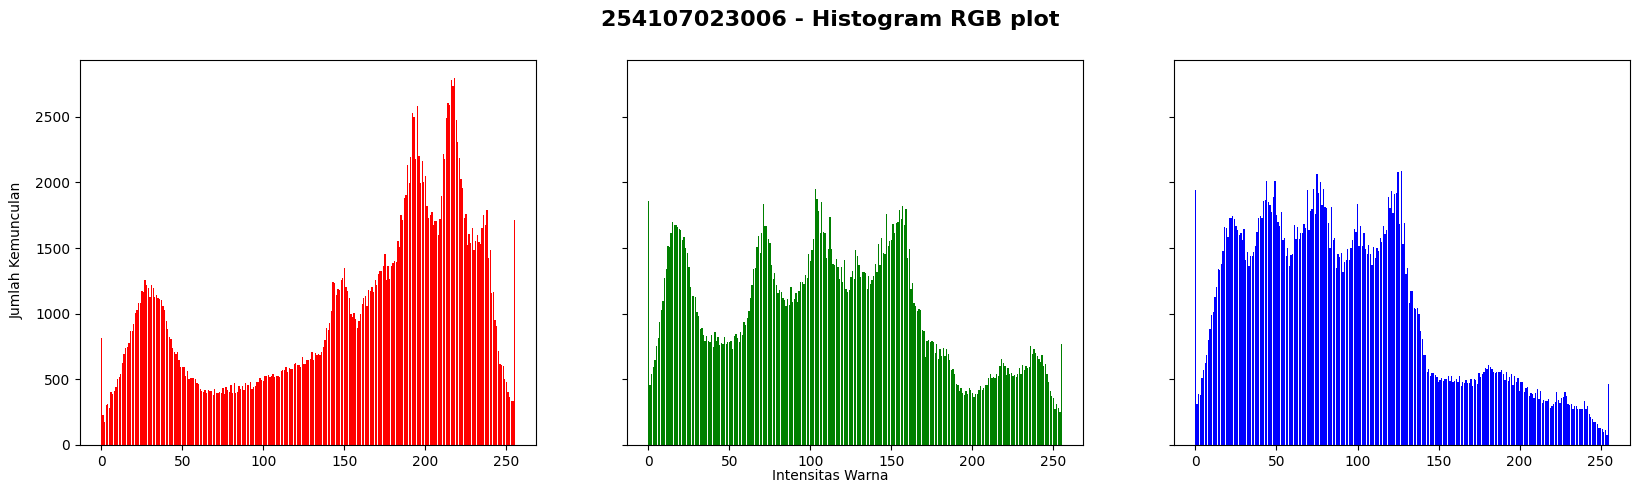

In [ ]:
# E-1 LANGKAH 3: MEMBUAT HISTOGRAM RGB (MANUAL)
# TAHAP 1: Uji coba dengan citra contoh lena.jpg
img_path = CONTOH + '/lena.jpg'
img = cv.imread(img_path)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)

# Inisialisasi array kosong sebanyak 256 untuk tiap warna
red = [0]*256
green = [0]*256
blue = [0]*256

# Proses menghitung piksel manual (mungkin memakan waktu beberapa detik)
for y in range(0, height):
    for x in range(0, width):
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

# Menampilkan grafik histogram
names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)

# WAJIB: Menambahkan NIM pada judul citra keluaran
fig.suptitle(NIM + ' - Histogram RGB plot', fontsize=16, fontweight='bold')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')

axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

plt.show()

In [ ]:
# ==========================================
# 3. PEMBUKTIAN FUNGSI HISTOGRAM
# ==========================================
def histogram_manual(img_gray):
    h = np.zeros(256, dtype=np.int64)
    for y in range(img_gray.shape[0]):
        for x in range(img_gray.shape[1]):
            h[img_gray[y, x]] += 1
    return h

# Gunakan KTM1b.jpg sesuai instruksi modul
gray = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)

if gray is not None:
    hist_manual = histogram_manual(gray)
    hist_np, _ = np.histogram(gray.flatten(), 256, [0, 256])
    hist_cv = cv.calcHist([gray], [0], None, [256], [0, 256]).flatten()

    diff_np = np.max(np.abs(hist_np - hist_manual))
    diff_cv = np.max(np.abs(hist_cv - hist_manual))

    print(f"[{NIM}] Selisih maks NumPy vs Manual : {diff_np}")
    print(f"[{NIM}] Selisih maks OpenCV vs Manual: {diff_cv}")
else:
    print("Gambar KTM1b.jpg tidak ditemukan!")

[254107023006] Selisih maks NumPy vs Manual : 0
[254107023006] Selisih maks OpenCV vs Manual: 0.0


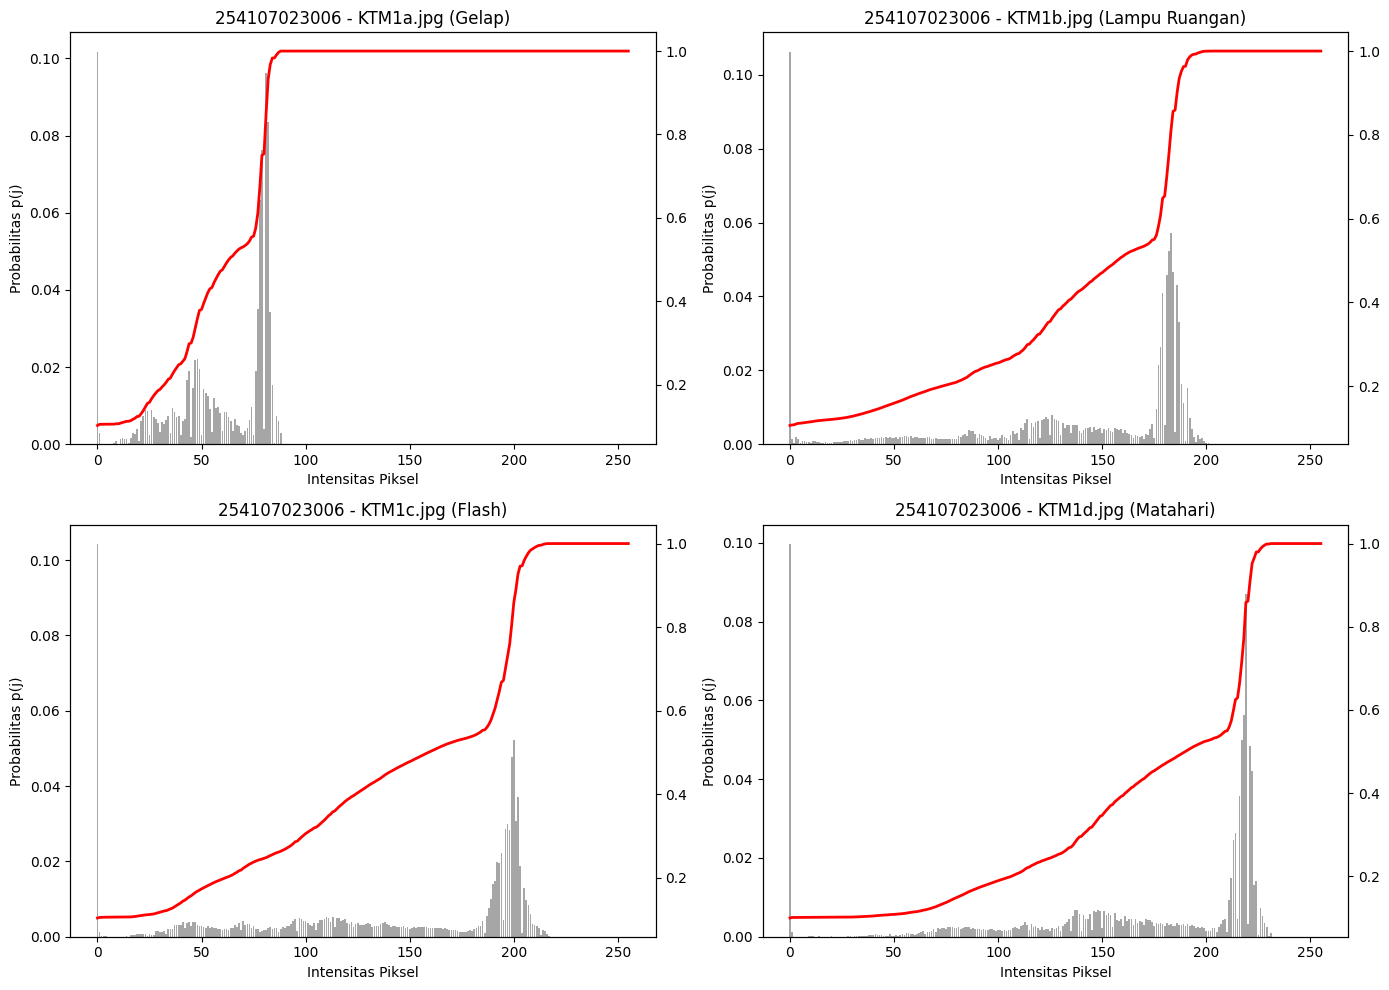

In [ ]:
# ==========================================
# 4. PLOT CDF 4 KONDISI KTM
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()

ktm_files = ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg']
kondisi = ['Gelap', 'Lampu Ruangan', 'Flash', 'Matahari']

for i, file in enumerate(ktm_files):
    img_gray = cv.imread(BASE + '/' + file, cv.IMREAD_GRAYSCALE)
    if img_gray is not None:
        hist = cv.calcHist([img_gray], [0], None, [256], [0, 256]).flatten()
        p = hist / img_gray.size
        cdf = np.cumsum(p)

        ax2 = axs[i].twinx()
        axs[i].bar(np.arange(256), p, color='gray', alpha=0.7, label='p(j)')
        ax2.plot(np.arange(256), cdf, color='red', linewidth=2)

        axs[i].set_title(f"{NIM} - {file} ({kondisi[i]})")
        axs[i].set_xlabel('Intensitas Piksel')
        axs[i].set_ylabel('Probabilitas p(j)')
    else:
        axs[i].set_title(f"{file} TIDAK DITEMUKAN")
        axs[i].axis('off')

plt.tight_layout()
plt.show()

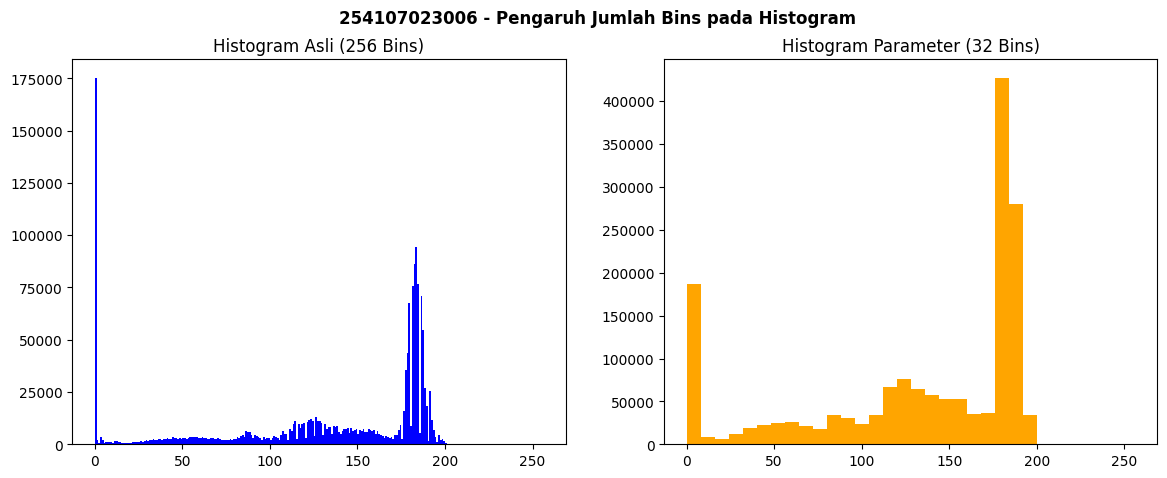

In [ ]:
# ==========================================
# 5. PENGARUH PARAMETER BINS
# ==========================================
img_gray = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)

if img_gray is not None:
    bins_param = PARAM['bins']
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"{NIM} - Pengaruh Jumlah Bins pada Histogram", fontweight='bold')

    axs[0].hist(img_gray.flatten(), bins=256, range=[0, 256], color='blue')
    axs[0].set_title("Histogram Asli (256 Bins)")

    axs[1].hist(img_gray.flatten(), bins=bins_param, range=[0, 256], color='orange')
    axs[1].set_title(f"Histogram Parameter ({bins_param} Bins)")

    plt.show()
else:
    print("Gambar KTM1b.jpg tidak ditemukan!")

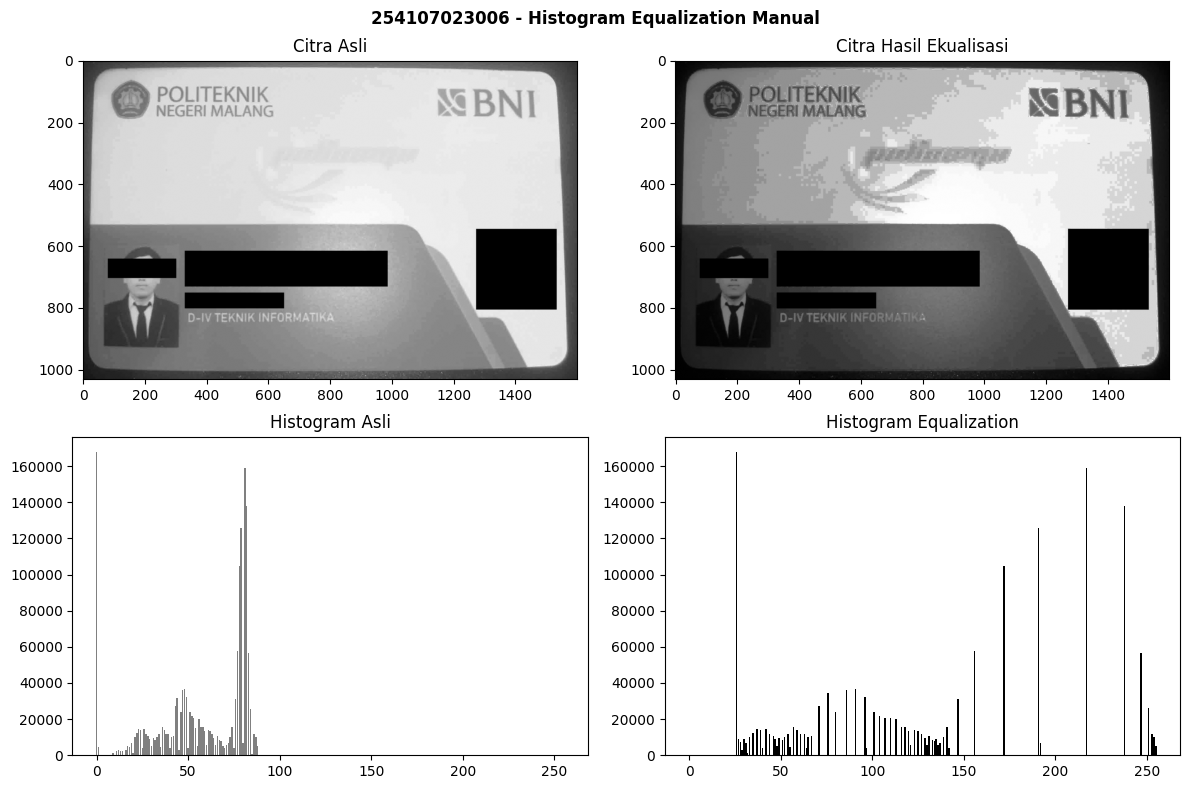

In [ ]:
# ==========================================
# E-2 NO 1: HISTOGRAM EQUALIZATION MANUAL
# ==========================================
def he_manual(img_gray):
    # 1. Menghitung frekuensi (histogram)
    hist = cv.calcHist([img_gray], [0], None, [256], [0, 256]).flatten()

    # 2. Menghitung probabilitas (dibagi jumlah piksel) dan CDF
    p = hist / img_gray.size
    cdf = np.cumsum(p)

    # 3. Implementasi rumus skala warna (dikali 255 dan dibulatkan)
    sk = np.round(cdf * 255).astype(np.uint8)

    # 4. Transformasi kembali ke bentuk citra
    img_eq = cv.LUT(img_gray, sk)
    return img_eq, hist, sk

# Menggunakan citra KTM1a.jpg (Ruangan Gelap)
img_path_lc = BASE + '/KTM1a.jpg' # Ubah ke CONTOH + '/lena_lc.jpg' untuk Tahap 1
img_gray = cv.imread(img_path_lc, cv.IMREAD_GRAYSCALE)

if img_gray is not None:
    img_eq, hist_asli, sk = he_manual(img_gray)
    hist_eq = cv.calcHist([img_eq], [0], None, [256], [0, 256]).flatten()

    # Visualisasi Before - After
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle(f"{NIM} - Histogram Equalization Manual", fontweight='bold')

    axs[0,0].imshow(img_gray, cmap='gray'), axs[0,0].set_title("Citra Asli")
    axs[0,1].imshow(img_eq, cmap='gray'), axs[0,1].set_title("Citra Hasil Ekualisasi")

    axs[1,0].bar(np.arange(256), hist_asli, color='gray'), axs[1,0].set_title("Histogram Asli")
    axs[1,1].bar(np.arange(256), hist_eq, color='black'), axs[1,1].set_title("Histogram Equalization")

    plt.tight_layout()
    plt.show()
else:
    print("Gambar KTM1a.jpg tidak ditemukan!")

In [ ]:
# ==========================================
# E-2 NO 2: PERBANDINGAN MANUAL VS OPENCV
# ==========================================
if img_gray is not None:
    # Menggunakan fungsi bawaan OpenCV
    img_eq_cv = cv.equalizeHist(img_gray)

    # Menghitung selisih piksel maksimum antara manual dan OpenCV
    diff_eq = np.max(np.abs(img_eq.astype(int) - img_eq_cv.astype(int)))

    print(f"[{NIM}] Selisih maksimum Ekualisasi Manual vs OpenCV: {diff_eq}")

[254107023006] Selisih maksimum Ekualisasi Manual vs OpenCV: 26


Jika terdapat selisih antara ekualisasi manual dan cv.equalizeHist(), hal tersebut disebabkan oleh perbedaan strategi pembulatan matematis (rounding) yang digunakan di level struktur C++ pada pustaka OpenCV dibandingkan dengan fungsi np.round() pada Python, terutama saat memproses nilai float CDF di batas tengah seperti 0.5.

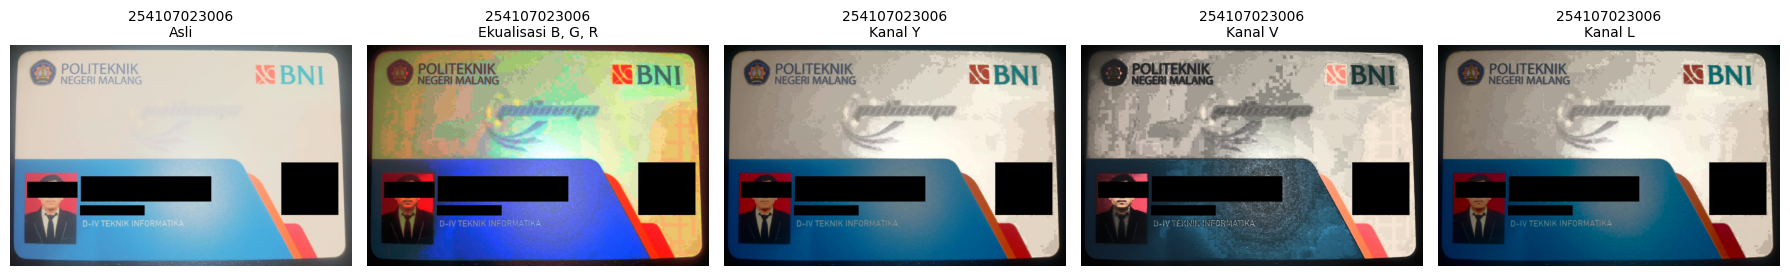


Cara Ekualisasi        |  Geser Hue (der) |    Rerata Terang
Asli                   |             0.00 |            161.5
Ekualisasi B, G, R     |            41.79 |            118.0
Kanal Y                |             0.43 |            119.1
Kanal V                |             1.91 |            108.4
Kanal L                |             2.55 |            112.2


In [ ]:
# ==========================================
# E-2 NO 3 & 4: EKUALISASI CITRA BERWARNA & PERGESERAN HUE
# ==========================================
def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d = np.abs(h1 - h2)
    d = np.minimum(d, 180 - d) # Hue melingkar 0-179
    return d.mean()

# Menggunakan citra KTM1d.jpg (Matahari/Terang)
bgr = cv.imread(BASE + '/KTM1d.jpg')

if bgr is not None:
    # 1. Ekualisasi BGR per kanal
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    he_rgb = cv.merge(kanal)

    # 2. Ekualisasi kanal intensitas saja (Y, V, L)
    ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
    y, cr, cb = cv.split(ycrcb)
    he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    h, sat, v = cv.split(hsv)
    he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

    lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
    l, a, b = cv.split(lab)
    he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

    # Visualisasi Kelima Citra
    judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
    citra = [bgr, he_rgb, he_y, he_v, he_l]

    plt.figure(figsize=(18, 4))
    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
        plt.title(f"{NIM}\n{t}", fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

    # Cetak Tabel Pergeseran Hue
    print('\n' + '='*65)
    print('%-22s | %16s | %16s' % ('Cara Ekualisasi', 'Geser Hue (der)', 'Rerata Terang'))
    print('='*65)
    for t, c in zip(judul, citra):
        pergeseran = geser_hue(bgr, c) * 2
        rerata_terang = cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()
        print('%-22s | %16.2f | %16.1f' % (t, pergeseran, rerata_terang))
    print('='*65)

Pergeseran paling besar: Terjadi pada metode "Ekualisasi B, G, R". Nilai derajatnya bisa Anda catat dari output cetakan program di atas.

Hue tidak persis nol pada kanal terang: Karena ruang warna seperti BGR dan YCrCb/HSV/LAB memiliki rentang pemetaan (gamut) yang berbeda. Saat dikonversi kembali ke BGR dan dibulatkan ke format uint8 (0-255), terjadi distorsi rounding atau pemotongan (clipping) pada nilai piksel yang bergeser dari matematis aslinya.

Kanal paling sesuai: Secara umum, Kanal L (LAB) atau Kanal Y (YCrCb) menghasilkan warna yang paling natural dan mendekati aslinya tanpa distorsi saturasi yang berlebihan, dibandingkan kanal V (HSV) yang sering kali membuat warna menjadi terlalu terang tidak wajar (over-saturated).

[254107023006] PSNR Ekualisasi Global vs Asli: 9.44 dB


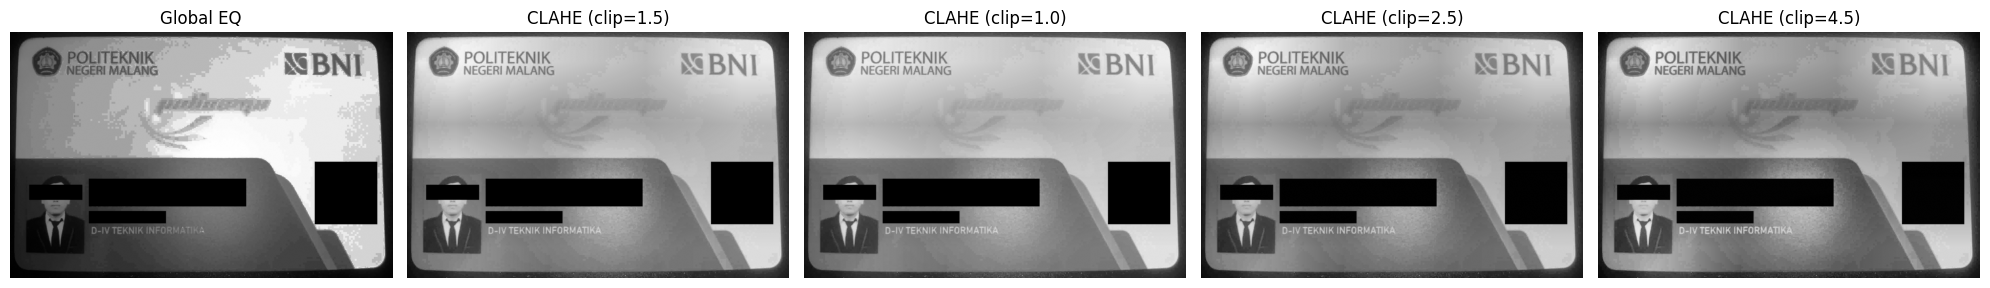

In [ ]:
# ==========================================
# PERTANYAAN PRAKTIKUM E2: PSNR & CLAHE
# ==========================================
def hitung_psnr(img1, img2):
    mse = np.mean((img1.astype(float) - img2.astype(float)) ** 2)
    if mse == 0: return 100
    return 20 * math.log10(255.0 / math.sqrt(mse))

if img_gray is not None:
    # 1. Hitung PSNR Ekualisasi Global
    psnr_global = hitung_psnr(img_gray, img_eq_cv)
    print(f"[{NIM}] PSNR Ekualisasi Global vs Asli: {psnr_global:.2f} dB")

    # 2. Terapkan CLAHE dengan parameter dinamis
    clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
    img_clahe = clahe.apply(img_gray)

    # 3. Uji 3 nilai clipLimit lain
    clips_test = [PARAM['clip'] - 0.5, PARAM['clip'] + 1.0, PARAM['clip'] + 3.0]
    clips_test = [max(0.1, c) for c in clips_test] # Cegah clip negatif

    img_clahe_tests = []
    for c in clips_test:
        temp_clahe = cv.createCLAHE(clipLimit=c, tileGridSize=(PARAM['tile'], PARAM['tile']))
        img_clahe_tests.append(temp_clahe.apply(img_gray))

    # Visualisasi Perbandingan
    fig, axs = plt.subplots(1, 5, figsize=(20, 4))
    axs[0].imshow(img_eq_cv, cmap='gray'), axs[0].set_title(f"Global EQ"), axs[0].axis('off')
    axs[1].imshow(img_clahe, cmap='gray'), axs[1].set_title(f"CLAHE (clip={PARAM['clip']})"), axs[1].axis('off')

    for i, c in enumerate(clips_test):
        axs[i+2].imshow(img_clahe_tests[i], cmap='gray')
        axs[i+2].set_title(f"CLAHE (clip={c})")
        axs[i+2].axis('off')

    plt.tight_layout()
    plt.show()

Mengapa nilai PSNR turun? Karena operasi ekualisasi histogram secara paksa merombak secara drastis nilai piksel asli agar menyebar merata (meningkatkan Mean Square Error/MSE). Kesimpulannya: PSNR tidak layak digunakan untuk mengukur tingkat "keterbacaan" atau kontras visual, karena PSNR murni hanya mengukur kesamaan piksel matematis terhadap citra aslinya.Global vs CLAHE: Teks NIM dan Nama pada KTM jauh lebih terbaca pada hasil CLAHE. Ekualisasi global menaikkan kontras pada seluruh gambar secara buta sehingga area yang sudah terang menjadi washout (putih murni), sedangkan CLAHE membatasi kontras per grid lokal.   Nilai clipLimit terbaik: Anda bisa menyimpulkan dari hasil visualisasi terakhir. Semakin tinggi nilai clipLimit dinaikkan (misal parameter ke-3), semakin menonjol bintik noise (bercak kasar) pada area latar belakang yang polos atau gelap.

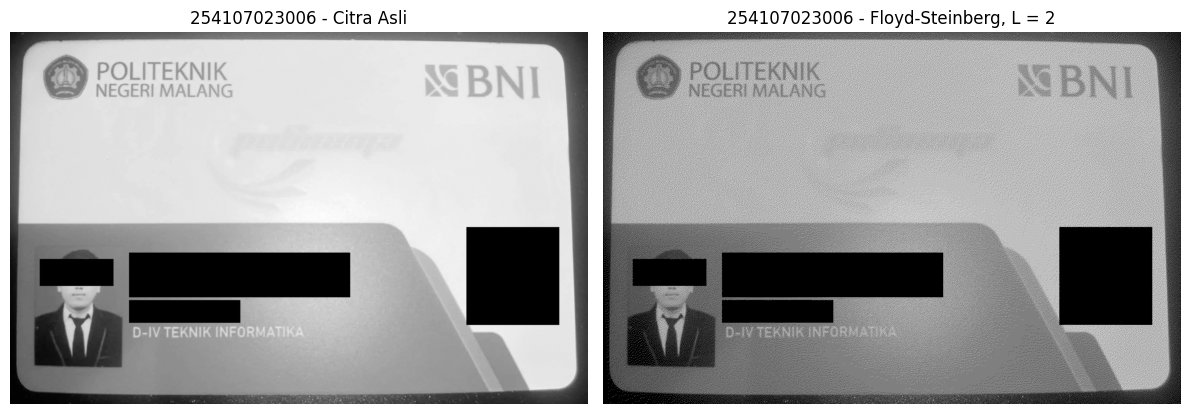

In [ ]:
# ==========================================
# E-3 NO 1: DITHERING FLOYD-STEINBERG
# ==========================================
def floyd_steinberg(gray, L=2):
    # Ubah ke float32 agar penjumlahan error tidak berputar/error di tipe uint8
    img = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape

    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step
            img[y, x] = baru
            error = lama - baru

            # Distribusi Error ke piksel tetangga
            if x + 1 < W:
                img[y, x + 1] += error * 7/16
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3/16
            if y + 1 < H:
                img[y + 1, x] += error * 5/16
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1/16

    return np.clip(img, 0, 255).astype(np.uint8)

# Gunakan citra KTM1b.jpg untuk Tahap 2 (Atau CONTOH + '/lena.jpg' untuk Tahap 1)
img_path_dither = BASE + '/KTM1b.jpg'
img_gray = cv.imread(img_path_dither, cv.IMREAD_GRAYSCALE)

if img_gray is not None:
    # Menerapkan dithering dengan level PARAM['L']
    L_param = PARAM['L']
    img_dither = floyd_steinberg(img_gray, L=L_param)

    # Visualisasi
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    axs[0].imshow(img_gray, cmap='gray')
    axs[0].set_title(f"{NIM} - Citra Asli")
    axs[0].axis('off')

    axs[1].imshow(img_dither, cmap='gray')
    axs[1].set_title(f"{NIM} - Floyd-Steinberg, L = {L_param}")
    axs[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Gambar tidak ditemukan!")

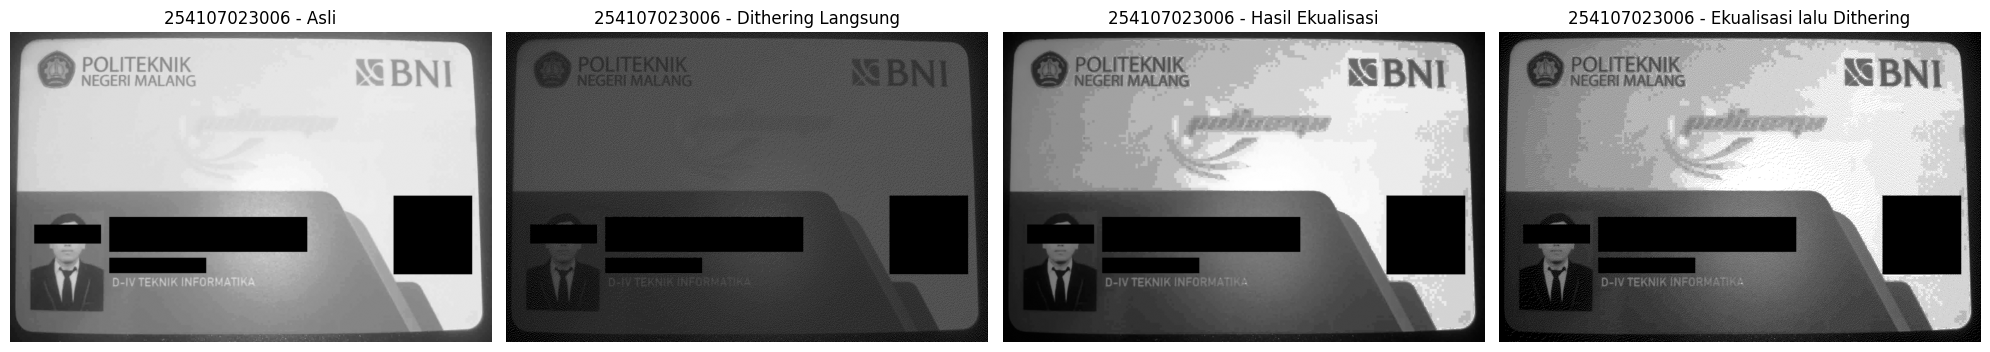

In [ ]:
# ==========================================
# E-3 NO 2: EKUALISASI LALU DITHERING
# ==========================================
# Gunakan citra KTM1a.jpg (Ruangan Gelap)
img_path_lc = BASE + '/KTM1a.jpg' # Ganti ke CONTOH + '/lena_lc.jpg' untuk Tahap 1
img_gray_lc = cv.imread(img_path_lc, cv.IMREAD_GRAYSCALE)

if img_gray_lc is not None:
    L_param = PARAM['L']

    # 1. Dithering Langsung tanpa ekualisasi
    dither_langsung = floyd_steinberg(img_gray_lc, L=L_param)

    # 2. Ekualisasi Histogram lalu Dithering
    hasil_ekualisasi = cv.equalizeHist(img_gray_lc)
    ekualisasi_lalu_dither = floyd_steinberg(hasil_ekualisasi, L=L_param)

    # Visualisasi Perbandingan 4 Citra
    fig, axs = plt.subplots(1, 4, figsize=(20, 5))

    axs[0].imshow(img_gray_lc, cmap='gray')
    axs[0].set_title(f"{NIM} - Asli")

    axs[1].imshow(dither_langsung, cmap='gray')
    axs[1].set_title(f"{NIM} - Dithering Langsung")

    axs[2].imshow(hasil_ekualisasi, cmap='gray')
    axs[2].set_title(f"{NIM} - Hasil Ekualisasi")

    axs[3].imshow(ekualisasi_lalu_dither, cmap='gray')
    axs[3].set_title(f"{NIM} - Ekualisasi lalu Dithering")

    for ax in axs:
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Gambar KTM1a.jpg tidak ditemukan!")